# Descriptive Implementation of SVM

Importing libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt

Generating Dataset

In [2]:
np.random.seed(42)

n = 100

# Class 0
class_0 = np.random.randn(n, 2) + np.array([2, 2])

# Class 1
class_1 = np.random.randn(n, 2) + np.array([6, 6])

# Combine data
X = np.vstack((class_0, class_1))

# Labels
y = np.hstack((
    np.zeros(n),
    np.ones(n)
))

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (200, 2)
y shape: (200,)


Plotting the dataset

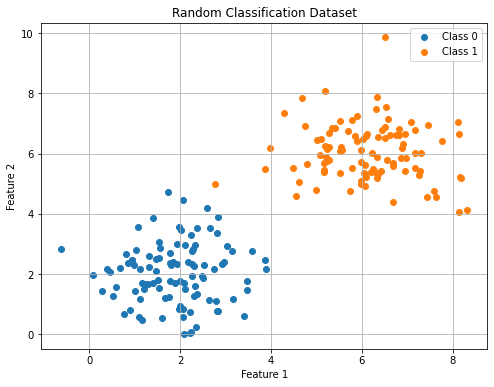

In [3]:
plt.figure(figsize=(8, 6))

plt.scatter(
    class_0[:, 0],
    class_0[:, 1],
    label="Class 0"
)

plt.scatter(
    class_1[:, 0],
    class_1[:, 1],
    label="Class 1"
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Random Classification Dataset")

plt.legend()
plt.grid(True)

plt.show()

In [4]:
y = np.where(y == 0, -1, 1)

print(np.unique(y))

[-1  1]


Train Test Split

In [5]:
indices = np.arange(len(X))

np.random.shuffle(indices)

train_size = int(0.8 * len(X))

train_indices = indices[:train_size]
test_indices = indices[train_size:]

X_train = X[train_indices]
y_train = y[train_indices]

X_test = X[test_indices]
y_test = y[test_indices]

print("Training samples:", len(X_train))
print("Testing samples :", len(X_test))

Training samples: 160
Testing samples : 40


Normalizing 

In [6]:
mean = np.mean(X_train, axis=0)
std = np.std(X_train, axis=0)

X_train = (X_train - mean) / std
X_test = (X_test - mean) / std

Initializing

In [7]:
# Number of features
n_features = X_train.shape[1]

# Initialize weights and bias
w = np.zeros(n_features)
b = 0.0

# Hyperparameters
learning_rate = 0.001
lambda_param = 0.01
epochs = 1000

print("Initial weights:", w)
print("Initial bias:", b)

Initial weights: [0. 0.]
Initial bias: 0.0


In [8]:
loss_history = []

for epoch in range(epochs):

    total_loss = 0

    for i in range(len(X_train)):

        # Decision function
        decision = np.dot(X_train[i], w) + b

        # Hinge loss condition
        condition = y_train[i] * decision

        if condition >= 1:

            # Correctly classified and outside margin
            dw = 2 * lambda_param * w
            db = 0

            loss = lambda_param * np.sum(w ** 2)

        else:

            # Misclassified or inside margin
            dw = (
                2 * lambda_param * w
                - y_train[i] * X_train[i]
            )

            db = -y_train[i]

            loss = (
                lambda_param * np.sum(w ** 2)
                + (1 - condition)
            )

        # Update weights
        w = w - learning_rate * dw

        # Update bias
        b = b - learning_rate * db

        total_loss += loss

    # Average loss
    average_loss = total_loss / len(X_train)

    loss_history.append(average_loss)

print("Training completed")

print("\nWeights:")
print(w)

print("\nBias:")
print(b)

Training completed

Weights:
[1.13193904 1.10693576]

Bias:
-0.023000000000000013


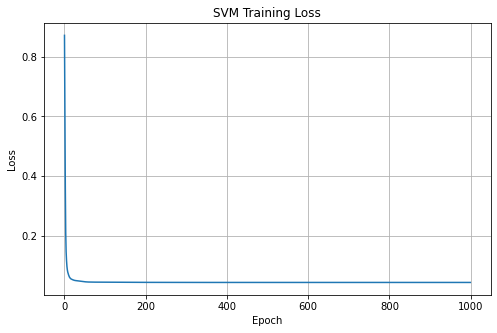

In [9]:
plt.figure(figsize=(8, 5))

plt.plot(loss_history)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title("SVM Training Loss")

plt.grid(True)

plt.show()

In [10]:
decision_values = np.dot(X_test, w) + b

y_pred = np.sign(decision_values)

print("Actual:")
print(y_test)

print("\nPredicted:")
print(y_pred)

Actual:
[ 1 -1  1 -1 -1 -1  1  1  1  1  1 -1 -1  1 -1 -1 -1  1 -1  1 -1 -1  1 -1
 -1  1 -1  1 -1 -1  1 -1  1  1 -1 -1 -1  1  1 -1]

Predicted:
[ 1. -1.  1. -1. -1. -1.  1.  1.  1.  1.  1. -1. -1.  1. -1. -1. -1.  1.
 -1.  1. -1. -1.  1. -1. -1.  1. -1.  1. -1. -1.  1. -1.  1.  1. -1. -1.
 -1.  1.  1. -1.]


In [11]:
correct = np.sum(y_pred == y_test)

accuracy = correct / len(y_test)

print("Correct predictions:", correct)
print("Total predictions  :", len(y_test))

print("Accuracy:", accuracy * 100, "%")

Correct predictions: 40
Total predictions  : 40
Accuracy: 100.0 %


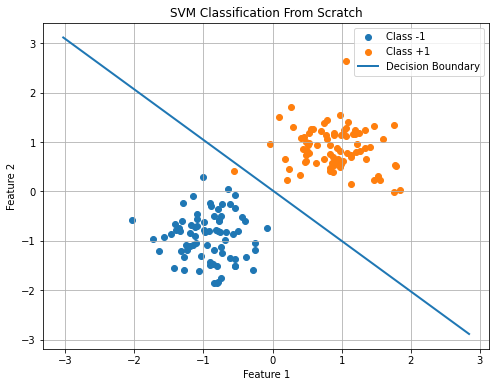

In [12]:
plt.figure(figsize=(8, 6))

# Plot Class -1
plt.scatter(
    X_train[y_train == -1, 0],
    X_train[y_train == -1, 1],
    label="Class -1"
)

# Plot Class +1
plt.scatter(
    X_train[y_train == 1, 0],
    X_train[y_train == 1, 1],
    label="Class +1"
)

# X values for boundary
x_values = np.linspace(
    X_train[:, 0].min() - 1,
    X_train[:, 0].max() + 1,
    200
)

# Decision boundary
y_boundary = -(w[0] * x_values + b) / w[1]

plt.plot(
    x_values,
    y_boundary,
    linewidth=2,
    label="Decision Boundary"
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")

plt.title("SVM Classification From Scratch")

plt.legend()
plt.grid(True)

plt.show()

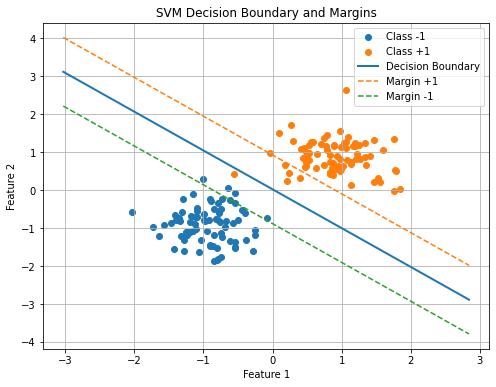

In [13]:
plt.figure(figsize=(8, 6))

# Class -1
plt.scatter(
    X_train[y_train == -1, 0],
    X_train[y_train == -1, 1],
    label="Class -1"
)

# Class +1
plt.scatter(
    X_train[y_train == 1, 0],
    X_train[y_train == 1, 1],
    label="Class +1"
)

x_values = np.linspace(
    X_train[:, 0].min() - 1,
    X_train[:, 0].max() + 1,
    200
)

# Decision boundary
boundary = -(w[0] * x_values + b) / w[1]

# +1 margin
margin_positive = -(w[0] * x_values + b - 1) / w[1]

# -1 margin
margin_negative = -(w[0] * x_values + b + 1) / w[1]

plt.plot(
    x_values,
    boundary,
    linewidth=2,
    label="Decision Boundary"
)

plt.plot(
    x_values,
    margin_positive,
    "--",
    label="Margin +1"
)

plt.plot(
    x_values,
    margin_negative,
    "--",
    label="Margin -1"
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")

plt.title("SVM Decision Boundary and Margins")

plt.legend()
plt.grid(True)

plt.show()